# Experiment 8 - 4-think that keeps only its last reasoning, in Cooking
A middle ground between r4-think (every reasoning stays in the context) and er4-think (no reasoning stays in the context, ephemeral):
here the reasoning of a self-evaluation stays in the context during the normal turns that follow it, and it is removed when the next self-evaluation starts.
So at any time the model sees at most one reasoning, its most recent one (`reads_own_reasoning="last"` in `LLMAgentSelfEvaluate`).

Same setup of the partial experiments 6e/7e: only lr4-think, only Cooking (levels 1-9) and only seeds 1-10, i.e. 90 games.
`prompt_version` selects the prompt: `"CoT"` is compared with experiment 7 (and 7e), `"default"` with experiment 6 (and 6e).


# Setup
On Google Colab this clones the repository, installs TextWorld and moves into `Code/Experiments`. Locally (e.g. in the Docker container) it does nothing.
The first time on a new Colab machine the installation takes a few minutes: restart the kernel after it (and then run all the cells), because it can update torch.


In [1]:
import os
import sys
import shutil
import subprocess

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    repo_url = "https://github.com/UPROOT01/LLMs-Play-Textual-Games.git"
    repo_dir = "/content/LLMs-Play-Textual-Games"
    if not os.path.isfile(f"{repo_dir}/Code/Self-evaluation/self_evaluation.py"):
        shutil.rmtree(repo_dir, ignore_errors=True) # leftover of a failed clone
        # sparse clone: only the folders needed by the experiments are downloaded (the whole Games folder is >1 GB)
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse", repo_url, repo_dir], check=True)
    else:
        # already cloned in this runtime: only fetch the new commits (fails safely instead of overwriting local results)
        subprocess.run(["git", "-C", repo_dir, "pull", "--ff-only"], check=True)
    # the clone may come from another experiment's notebook: add the folders this one needs
    subprocess.run(["git", "-C", repo_dir, "sparse-checkout", "add",
                    "Code/Self-evaluation", "Code/Games/coin_collector", "Code/Games/cooking",
                    "Code/Games/treasure_hunter", "Code/Experiments/Experiment 6", "Code/Experiments/Experiment 7"], check=True)
    # vllm: generation engine used by parallel_play (n_parallel > 1); it may replace the installed torch version
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "textworld", "vllm==0.31.0"], check=True)
    os.chdir(f"{repo_dir}/Code/Experiments")

print("Working directory:", os.getcwd())

Working directory: /content/LLMs-Play-Textual-Games/Code/Experiments


On Colab the results are saved on Google Drive, because the files of the Colab machine are deleted together with it.
If mounting fails, use the VS Code command *Colab: Mount Google Drive to Server...*

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
import torch

assert torch.cuda.is_available(), "No GPU available: connect to a Colab runtime with a GPU (e.g. T4)"
! nvidia-smi

Thu Oct  8 11:15:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   36C    P8             14W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
import pickle
sys.path.append("../Self-evaluation")

from self_evaluation import play, LLMAgentSelfEvaluate
from parallel_play import play_parallel

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

# Notebook variables

In [6]:
exp_number = 8
games_folder = "../Games"
seeds = range(1,11) # same seeds of e1-think and er4-think, first 10 seeds of r4/r10-think
n_episodes = 1
max_steps = 100
n = 4 # only lr4-think
prompt_version = "CoT" # "CoT" (compared with experiment 7) or "default" (compared with experiment 6)
compared_exp = 7 if prompt_version == "CoT" else 6

levels = {"coin_collector": 14, "cooking": 9, "treasure_hunter": 27}
game = "cooking"
run_levels = range(1, 10)

# games played at the same time, with the answers generated in batches (see Self-evaluation/parallel_play.py)
# 1 = one game at a time, with the normal play()
n_parallel = 4

# episodes stuck in a loop (at most loop_max_distinct different turns among the last loop_window) are stopped early
loop_window = 20
loop_max_distinct = 2

# new results and logs: on Colab they go to Google Drive, so they survive the deletion of the Colab machine
if IN_COLAB:
    assert os.path.isdir("/content/drive/MyDrive"), "Google Drive is not mounted: run the cell above"
    drive_folder = "/content/drive/MyDrive/LLMs-Play-Textual-Games"
else:
    drive_folder = "."
results_folder = f"{drive_folder}/Experiment {exp_number}/{prompt_version}" # one folder per prompt, same file names
print("Results folder:", results_folder)

with open(f"{games_folder}/max_scores_cooking.pickle", "rb") as f:
    max_scores_cooking = pickle.load(f)
os.makedirs(f"{results_folder}/logs/{game}", exist_ok=True)

Results folder: /content/drive/MyDrive/LLMs-Play-Textual-Games/Experiment 8/CoT


# Game running
The results are saved after every game: if the run is interrupted, running this cell again resumes from the first seed not yet played.
With `n_parallel > 1` the games end in any order, but each level's file only stores consecutive seeds: when interrupted, the games already finished after a missing seed are played again.

In [7]:
def results_path(level):
    return f"{results_folder}/lr{n}think_{game}_level{level}.pickle"

def make_agent(level, seed, show_speed):
    return LLMAgentSelfEvaluate(selfeval_turns=n,
                                reads_own_reasoning="last", # only the last reasoning stays in the context
                                random_selfeval=True,
                                prompt_version=prompt_version,
                                show_speed=show_speed,
                                log=f"{results_folder}/logs/{game}/lr{n}think_level{level}-seed{seed}.log")

def game_path(level, seed):
    return f"{games_folder}/{game}/level{level}-seed{seed}.z8"

saved = {} # level -> results of the seeds played so far, in seed order
for level in run_levels:
    saved[level] = []
    if os.path.exists(results_path(level)):
        with open(results_path(level), "rb") as f:
            saved[level] = pickle.load(f)

def save(level):
    with open(results_path(level), "wb") as f:
        pickle.dump(saved[level], f)

if n_parallel == 1:
    for level in run_levels:
        for seed in seeds[len(saved[level]):]: # skip the seeds already played
            results = play(make_agent(level, seed, show_speed=True), game_path(level, seed),
                           max_steps=max_steps, n_episodes=n_episodes,
                           loop_window=loop_window, loop_max_distinct=loop_max_distinct)
            saved[level].append(results[0])
            save(level)
else:
    ended_early = {} # (level, seed) -> results of the games that ended before a lower seed of their level

    def on_result(key, result):
        ended_early[key] = result
        level = key[0]
        # store the consecutive seeds only, so that resuming from len(saved[level]) stays correct
        while len(saved[level]) < len(seeds) and (level, seeds[len(saved[level])]) in ended_early:
            saved[level].append(ended_early.pop((level, seeds[len(saved[level])])))
        save(level)

    jobs = [((level, seed), lambda level=level, seed=seed: make_agent(level, seed, show_speed=False), game_path(level, seed))
            for level in run_levels for seed in seeds[len(saved[level]):]] # skip the seeds already played
    print(f"{len(jobs)} games to play")
    play_parallel(jobs, n_parallel=n_parallel, max_steps=max_steps,
                  loop_window=loop_window, loop_max_distinct=loop_max_distinct, on_result=on_result)

90 games to play


Parse safetensors files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading safetensors checkpoint shards:   0% Completed | 0/3 [00:00<?, ?it/s]


[rank0]:W1008 11:18:01.389000 665 torch/_inductor/utils.py:1953] Not enough SMs to use max_autotune_gemm mode
Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00, 13.29it/s]
2026-10-08 11:20:04,508 - INFO - core.py:564 - flashinfer.jit: Building JIT module sampling; this can take several minutes on first use.
Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:02<00:00, 14.59it/s]


1 games running, 0 waiting; 89 ended (25.0 games/hour); 4991 tokens/min overall

../Games/cooking/level1-seed4.z8 steps: 50; score: 5 / 5; time: 269 s
../Games/cooking/level1-seed5.z8 steps: 20; score: 1 / 5; time: 108 s
../Games/cooking/level1-seed2.z8 steps: 100; score: 4 / 5; time: 462 s
../Games/cooking/level1-seed1.z8 loop detected, steps: 77; score: 1 / 5; time: 505 s
../Games/cooking/level1-seed6.z8 steps: 24; score: 3 / 5; time: 129 s
../Games/cooking/level1-seed7.z8 steps: 28; score: 2 / 5; time: 86 s
../Games/cooking/level1-seed3.z8 steps: 100; score: 2 / 5; time: 895 s
../Games/cooking/level1-seed8.z8 steps: 100; score: 3 / 5; time: 631 s
../Games/cooking/level1-seed10.z8 loop detected, steps: 92; score: 2 / 5; time: 655 s
../Games/cooking/level2-seed2.z8 steps: 26; score: 1 / 8; time: 126 s
../Games/cooking/level1-seed9.z8 steps: 100; score: 2 / 5; time: 779 s
../Games/cooking/level2-seed1.z8 loop detected, steps: 99; score: 5 / 8; time: 428 s
../Games/cooking/level2-seed6.z8 steps: 33; score: 8 / 8; time: 178 s
../Games/cooking/level2-seed3.z8 steps: 1

# Comparison
Average normalized final score per level, with the number of seeds in brackets: lr4-think against r4-think (all the reasonings in the context)
and er4-think (no reasoning in the context), with 0- and e1-think as references. All on the first 10 seeds.
Execution times are not compared here: the episodes stopped because of a loop are shorter than in the other runs, and with `n_parallel > 1` the times are wall-clock times of games played together.


In [8]:
import numpy as np

models = ["0", "e1", "r4", "er4", "lr4"]

def results_file(model, level):
    if model.startswith("lr"): # this experiment
        folder = results_folder
    elif model.startswith("er"): # experiment 6e/7e, on Drive
        folder = f"{drive_folder}/Experiment {compared_exp}"
    else: # experiment 6/7, in the repository
        folder = f"./Experiment {compared_exp}"
    return f"{folder}/{model}think_{game}_level{level}.pickle"

def load_scores(model, level):
    """Normalized final scores of the first len(seeds) seeds, or None if the results do not exist."""
    path = results_file(model, level)
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        results_all_seeds = pickle.load(f)[:len(seeds)]
    final_scores = np.array([run[-1][1] for run in results_all_seeds], dtype=float)
    return final_scores / max_scores_cooking[level - 1]

print(f"{game}, prompt {prompt_version}")
print("level" + "".join(f"{model + '-think':>14}" for model in models))
for level in run_levels:
    row = []
    for model in models:
        scores = load_scores(model, level)
        row.append("-" if scores is None else f"{np.mean(scores):.2f} ({len(scores)})")
    print(f"{level:>5}" + "".join(f"{cell:>14}" for cell in row))


cooking, prompt CoT
level       0-think      e1-think      r4-think     er4-think     lr4-think
    1     0.06 (10)     0.56 (10)     0.28 (10)     0.46 (10)     0.50 (10)
    2     0.09 (10)     0.62 (10)     0.39 (10)     0.54 (10)     0.44 (10)
    3     0.13 (10)     0.64 (10)     0.31 (10)     0.40 (10)     0.53 (10)
    4     0.10 (10)     0.52 (10)     0.20 (10)     0.62 (10)     0.44 (10)
    5     0.05 (10)     0.55 (10)     0.29 (10)     0.45 (10)     0.53 (10)
    6     0.07 (10)     0.40 (10)     0.23 (10)     0.45 (10)     0.48 (10)
    7     0.09 (10)     0.42 (10)     0.20 (10)     0.29 (10)     0.40 (10)
    8     0.08 (10)     0.38 (10)     0.24 (10)     0.25 (10)     0.30 (10)
    9     0.04 (10)     0.18 (10)     0.11 (10)     0.13 (10)     0.17 (10)


## Graph
Average normalized final score per level, with its 90% bootstrap confidence interval, on the same seeds of the table.
The graph is also saved as a PDF in the `graphs` folder next to the results.

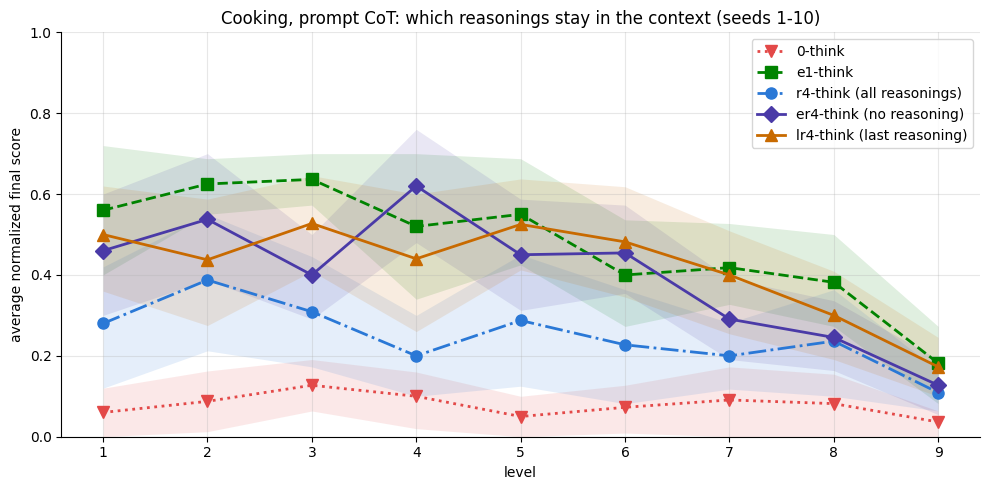

In [9]:
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

# same colors, line styles and markers of the graphs of experiments 6e/7e, plus lr4-think
styles = {"0":   dict(color="#e34948", linestyle=":",  marker="v"),
          "e1":  dict(color="#008300", linestyle="--", marker="s"),
          "r4":  dict(color="#2a78d6", linestyle="-.", marker="o"),
          "er4": dict(color="#4a3aa7", linestyle="-",  marker="D"),
          "lr4": dict(color="#c86a00", linestyle="-",  marker="^")}
labels = {"r4": "r4-think (all reasonings)", "er4": "er4-think (no reasoning)", "lr4": "lr4-think (last reasoning)"}

fig, ax = plt.subplots(figsize=(10, 5))
for model in models:
    x, y, low, high = [], [], [], []
    for level in run_levels:
        scores = load_scores(model, level)
        if scores is None or len(scores) < 2:
            continue
        ci = bootstrap((scores,), np.mean, method="basic", n_resamples=1000, confidence_level=0.9).confidence_interval
        x.append(level)
        y.append(np.mean(scores))
        low.append(max(ci.low, 0) if np.isfinite(ci.low) else y[-1])
        high.append(min(ci.high, 1) if np.isfinite(ci.high) else y[-1])
    if not x:
        continue
    ax.fill_between(x, low, high, color=styles[model]["color"], alpha=0.12, linewidth=0)
    ax.plot(x, y, label=labels.get(model, f"{model}-think"), linewidth=2, markersize=8, **styles[model])
ax.set_title(f"{game.capitalize()}, prompt {prompt_version}: which reasonings stay in the context (seeds {seeds[0]}-{seeds[-1]})")
ax.set_xlabel("level")
ax.set_ylabel("average normalized final score")
ax.set_xticks(list(run_levels))
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
fig.tight_layout()

os.makedirs(f"{results_folder}/graphs", exist_ok=True)
fig.savefig(f"{results_folder}/graphs/lr_vs_r_er_{game}.pdf", bbox_inches="tight")
plt.show()
